# Module 1 — Probability Fundamentals

**Probability Simulation Laboratory** · Module 1 of 8

## Learning objectives
By the end of this notebook you should be able to

1. describe a random experiment with a sample space $\Omega$, events and a probability measure $P$;
2. state Kolmogorov's axioms and derive elementary rules from them (see `research_notes/01_probability_fundamentals.md`);
3. compute probabilities exactly by enumeration and approximately by simulation, and quantify the difference;
4. use conditional probability, independence and Bayes' theorem correctly (and spot the classic mistakes);
5. use combinatorial reasoning (birthday problem, Monty Hall) and check it by simulation.

## How to read this notebook
Every experiment follows the same twelve-part research format (A–L): title, question, mathematics, prediction,
design, code, results, theory-versus-experiment comparison, interpretation, limitations, conclusion, further work.
**Do the paper exercises in `exercises/` before looking at the code**, and treat every simulation as *evidence and
intuition*, never as proof.

## Research objective
Investigate how empirical probabilities (relative frequencies from simulation) compare with theoretical
probabilities under repeated random experiments.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "01_probability_fundamentals" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import fundamentals as f      # module-specific code lives in 01_probability_fundamentals/src/fundamentals.py

## 1. Mathematical background

**Sample space and events.** A random experiment has a set $\Omega$ of possible outcomes $\omega$. An *event* is a
subset $A \subseteq \Omega$; it *occurs* if the realised outcome $\omega \in A$. Event algebra mirrors set algebra:
$A\cup B$ ("A or B"), $A\cap B$ ("A and B"), $A^c$ ("not A"). Probabilities are assigned to events in a family
$\mathcal F$ (a $\sigma$-algebra; for finite $\Omega$ take all subsets).

**Kolmogorov's axioms.** A probability measure $P:\mathcal F\to\mathbb R$ satisfies

1. $P(A)\ge 0$ for every event $A$;
2. $P(\Omega)=1$;
3. for pairwise disjoint $A_1, A_2,\dots$: $P\big(\bigcup_i A_i\big)=\sum_i P(A_i)$.

Everything else is derived. For example $P(A^c)=1-P(A)$ and $P(A\cup B)=P(A)+P(B)-P(A\cap B)$.

**Classical probability.** If $\Omega$ is finite and outcomes are *equally likely*, $P(A)=|A|/|\Omega|$.
The equal-likelihood clause is a modelling assumption — it is true for fair dice, false for loaded ones.

**Conditional probability.** For $P(B)>0$,
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}.$$
$P(A\mid B)$ is the probability of $A$ in the *reduced* sample space $B$.

**Independence.** $A$ and $B$ are independent iff $P(A\cap B)=P(A)P(B)$ (equivalently $P(A\mid B)=P(A)$ when $P(B)>0$).
Events $A_1,\dots,A_k$ are *mutually* independent iff the product rule holds for **every** sub-collection. Pairwise
independence is strictly weaker (Experiment 1.4 shows an example).

**Law of total probability and Bayes' theorem.** If $B_1,\dots,B_k$ partition $\Omega$ and each $P(B_j)>0$,
$$P(A)=\sum_j P(A\mid B_j)P(B_j),\qquad P(B_i\mid A)=\frac{P(A\mid B_i)P(B_i)}{\sum_j P(A\mid B_j)P(B_j)}.$$
Here $P(B_i)$ is the *prior*, $P(A\mid B_i)$ the *likelihood* and $P(B_i\mid A)$ the *posterior*.

**Bernoulli trials and combinatorics.** A Bernoulli($p$) trial has two outcomes (1 with probability $p$).
For $n$ independent trials the number of successes $K$ satisfies $P(K=k)=\binom nk p^k(1-p)^{n-k}$, where
$\binom nk=\frac{n!}{k!(n-k)!}$ counts the ways to choose which $k$ trials succeed.

**Empirical probability.** After $n$ repetitions with $n_A$ occurrences of $A$, the *relative frequency* is
$f_n(A)=n_A/n$. If the repetitions are independent, $n_A\sim\text{Binomial}(n,P(A))$, so
$$\mathbb E[f_n(A)]=P(A),\qquad \operatorname{Var}[f_n(A)]=\frac{P(A)(1-P(A))}{n},\qquad \operatorname{SE}=\sqrt{\frac{P(A)(1-P(A))}{n}}.$$
$f_n(A)$ is a *random variable*; $P(A)$ is a *fixed number*. (The Law of Large Numbers, Module 3, says $f_n(A)\to P(A)$.)

**Simulating an event.** If $U\sim\text{Uniform}[0,1)$ then $P(U<p)=p$, so $\mathbf 1\{U<p\}$ is Bernoulli($p$).
In Python, an event is a boolean array, and its relative frequency is that array's `.mean()`.

## Experiment 1.1

**A. Experiment title.** Convergence of the relative frequency $f_n$ of heads in $n$ independent Bernoulli($\tfrac12$) trials, and the $\sqrt{p(1-p)/n}$ error scale.

**B. Research question.** How quickly, and in what sense, does the proportion of heads approach $1/2$ as the number of tosses grows?

**C. Mathematical foundation.**

Let $X_i\sim\text{Bernoulli}(p)$ i.i.d., $f_n=\frac1n\sum_{i=1}^n X_i$. Then $\mathbb E f_n=p$ and
$\operatorname{Var} f_n = p(1-p)/n$. Hence the typical size of $|f_n-p|$ is the *standard error*
$\sigma_n=\sqrt{p(1-p)/n}$ — it shrinks like $n^{-1/2}$, not $n^{-1}$. By the Central Limit Theorem (Module 4),
$f_n\approx\mathcal N(p,\sigma_n^2)$, so $|f_n-p|\le 3\sigma_n$ with probability about $99.7\%$ *at a fixed $n$*.

**D. Theoretical prediction.**

(i) $\mathbb E[f_n]=\tfrac12$ for every $n$. (ii) $|f_n-\tfrac12|$ is of order $\tfrac{1}{2\sqrt n}$: about $0.05$ at $n=100$,
$0.0158$ at $n=1{,}000$, $0.005$ at $n=10{,}000$. (iii) Across many independent repetitions at $n=100$, $f_{100}$ has mean $0.5$ and
standard deviation $0.05$, and its distribution is that of Binomial$(100,\tfrac12)/100$.

**E. Experimental design.**

Simulate 5 independent sequences of $n=100{,}000$ fair-coin tosses ($p=\tfrac12$) and track the running frequency.
Then repeat the experiment $20{,}000$ times at $n=100$ to look at the *sampling distribution* of $f_{100}$.
Assumptions: independence of tosses and a constant success probability.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

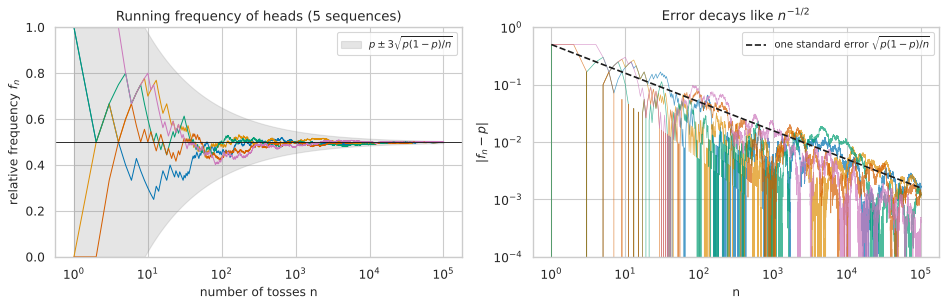

PosixPath('/home/claude/probability-simulation-laboratory/01_probability_fundamentals/results/exp1_1_running_frequency.png')

In [3]:
# F. Python implementation ------------------------------------------------------
# X_i ~ Bernoulli(p)        ->  f.simulate_bernoulli(n, p, rng)   (1{U < p})
# f_k = (X_1+...+X_k)/k     ->  f.running_frequency(x)            (cumsum / k)
# 3 * sqrt(p(1-p)/n)        ->  f.frequency_envelope(n_grid, p)
n, p = 100_000, 0.5
n_axis = np.arange(1, n + 1)
paths = [f.running_frequency(f.simulate_bernoulli(n, p, rng)) for _ in range(5)]
env = f.frequency_envelope(n_axis, p, z=3.0)

# G. Results and visualisation ---------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for fr in paths:
    ax[0].plot(n_axis, fr, lw=0.9)
ax[0].fill_between(n_axis, np.clip(p - env, 0, 1), np.clip(p + env, 0, 1), color="grey", alpha=0.2, label=r"$p \pm 3\sqrt{p(1-p)/n}$")
ax[0].axhline(p, color="k", lw=0.8)
ax[0].set(xscale="log", ylim=(0, 1), xlabel="number of tosses n", ylabel=r"relative frequency $f_n$", title="Running frequency of heads (5 sequences)")
ax[0].legend()

for fr in paths:
    ax[1].plot(n_axis, np.abs(fr - p), lw=0.6, alpha=0.7)
ax[1].plot(n_axis, np.sqrt(p * (1 - p) / n_axis), "k--", lw=1.5, label=r"one standard error $\sqrt{p(1-p)/n}$")
ax[1].set(xscale="log", yscale="log", ylim=(1e-4, 1), xlabel="n", ylabel=r"$|f_n - p|$", title="Error decays like $n^{-1/2}$")
ax[1].legend()
fig.tight_layout()
save_fig(fig, RESULTS, "exp1_1_running_frequency.png")

In [4]:
# H. Theoretical versus empirical: checkpoints along the first sequence --------------
rows = []
for k in [10, 100, 1_000, 10_000, 100_000]:
    fk = paths[0][k - 1]
    se = np.sqrt(p * (1 - p) / k)
    lo, hi = wilson_interval(int(round(fk * k)), k)
    rows.append(dict(n=k, f_n=fk, abs_error=abs(fk - p), theoretical_SE=se, z_score=(fk - p) / se,
                     wilson_95_low=lo, wilson_95_high=hi, interval_contains_p=lo <= p <= hi))
checkpoint_table = pd.DataFrame(rows).set_index("n")
checkpoint_table.to_csv(RESULTS / "exp1_1_checkpoints.csv")
display(checkpoint_table)

# Sampling distribution of f_100 over 20,000 repetitions
reps, n100 = 20_000, 100
f100 = (rng.random((reps, n100)) < p).mean(axis=1)
exact_pmf = stats.binom.pmf(np.arange(n100 + 1), n100, p)
emp_pmf = np.bincount(np.rint(f100 * n100).astype(int), minlength=n100 + 1) / reps
print(f"mean(f_100) = {f100.mean():.4f}   (theory 0.5)")
print(f"sd(f_100)   = {f100.std(ddof=1):.4f}   (theory {np.sqrt(p*(1-p)/n100):.4f})")
print(f"total-variation distance to Binomial(100, 1/2)/100 = {0.5*np.abs(emp_pmf-exact_pmf).sum():.4f}")

mean(f_100) = 0.4995   (theory 0.5)
sd(f_100)   = 0.0499   (theory 0.0500)
total-variation distance to Binomial(100, 1/2)/100 = 0.0162


,f_n,abs_error,theoretical_SE,z_score,wilson_95_low,wilson_95_high,interval_contains_p
n,,,,,,,
10,0.30000,0.20000,0.15811,-1.26491,0.10779,0.60322,True
100,0.45000,0.05000,0.05000,-1.00000,0.35615,0.54755,True
1000,0.49500,0.00500,0.01581,-0.31623,0.46409,0.52595,True
10000,0.49660,0.00340,0.00500,-0.68000,0.48680,0.50640,True
100000,0.49837,0.00163,0.00158,-1.03090,0.49527,0.50147,True


**H. Theoretical versus empirical comparison.**

The z-scores in the table are all of order 1 — empirical frequencies sit within about one or two standard errors
of $0.5$, and the Wilson intervals contain $p$ — which is exactly what theory predicts. The right panel shows the
error following the $n^{-1/2}$ line (note the *log-log* scale: a slope of $-\tfrac12$). Across 20,000 repetitions
the mean and standard deviation of $f_{100}$ match $0.5$ and $0.05$ closely, and the total-variation distance to the
exact binomial law is small (it is not zero: $20{,}000$ repetitions cannot resolve the pmf perfectly).

**I. Interpretation.**

Relative frequency is an *estimator* of $P(\text{heads})$ whose accuracy improves only like $1/\sqrt n$:
to gain one more decimal digit of precision you need roughly $100\times$ more tosses. The grey band is *pointwise*:
for any single $n$ about $99.7\%$ of sequences lie inside it. It is not a uniform guarantee: a single sequence
watched over a huge range of $n$ can leave the band at *some* $n$ (this is the content of the law of the iterated logarithm).

**J. Limitations.**

Pseudo-random numbers are deterministic given the seed. The independence of tosses is an assumption of the model
that the generator approximates extremely well but not perfectly. Five sequences is a tiny sample for judging a
distribution — the 20,000-repetition study addresses that. Comparing one frequency with $p$ cannot *prove* $p=\tfrac12$.

**K. Research conclusion.**

Simulation supports the theory that $f_n$ concentrates around $p$ at rate $n^{-1/2}$ and that its spread at fixed $n$ is
$\sqrt{p(1-p)/n}$. This is evidence, not proof; the proof is Chebyshev/Law of Large Numbers (Module 3).

**L. Further investigation.**

Repeat with $p=0.01$ (rare events): when is the normal approximation to the Binomial poor? Compare Wilson and Wald
intervals' coverage by simulation. Then ask: what is the distribution of the *time of the last excursion outside* the
band (the arcsine laws of Module 6 are related)?

## Experiment 1.2

**A. Experiment title.** Exact versus simulated probability mass function of the sum $S=D_1+D_2$ of two fair dice.

**B. Research question.** Does a simulated distribution of the sum agree with the exact distribution obtained by enumerating the sample space, and how can we test that?

**C. Mathematical foundation.**

$\Omega=\{1,\dots,6\}^2$ has $36$ equally likely ordered pairs, so $P(S=s)=\dfrac{\#\{(d_1,d_2):d_1+d_2=s\}}{36}$,
which gives the triangular pmf $\frac{6-|s-7|}{36}$ for $s=2,\dots,12$. Note the outcome $(1,6)$ and $(6,1)$ are *different*
outcomes: treating "sum $=7$" as a single outcome is the classic error.
For $n$ simulated rolls the counts $(N_2,\dots,N_{12})$ are multinomial with expected counts $nP(S=s)$, which we test with
Pearson's $\chi^2=\sum_s\frac{(N_s-nP(S=s))^2}{nP(S=s)}$ (approximately $\chi^2_{10}$ when the model is right).

**D. Theoretical prediction.**

$P(S=7)=\tfrac16\approx0.1667$ is the most likely sum; $P(S=2)=P(S=12)=\tfrac1{36}\approx0.0278$. With $n=100{,}000$ rolls the empirical
frequencies should be within a few $\sqrt{P(1-P)/n}$ (about $0.001$) of the exact values, and the $\chi^2$ test should *not* reject.

**E. Experimental design.**

Enumerate $\Omega$ exactly (with `fractions.Fraction`), simulate $n=100{,}000$ rolls of two dice, compare frequencies, compute the
total-variation distance and a $\chi^2$ goodness-of-fit test. (If the true model is correct the p-value is Uniform$(0,1)$: it is
*not* expected to be close to 1.)

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,exact (fraction),exact,empirical,abs_diff,std_error,diff_in_SE
sum,,,,,,
2,1/36,0.02778,0.02759,0.00019,0.00052,-0.36134
3,1/18,0.05556,0.05528,0.00028,0.00072,-0.38041
4,1/12,0.08333,0.08397,0.00064,0.00087,0.72845
5,1/9,0.11111,0.11116,0.00005,0.00099,0.04919
6,5/36,0.13889,0.13810,0.00079,0.00109,-0.72136
7,1/6,0.16667,0.16711,0.00044,0.00118,0.37618
8,5/36,0.13889,0.13944,0.00055,0.00109,0.50394
9,1/9,0.11111,0.11104,0.00007,0.00099,-0.07155
10,1/12,0.08333,0.08304,0.00029,0.00087,-0.33562


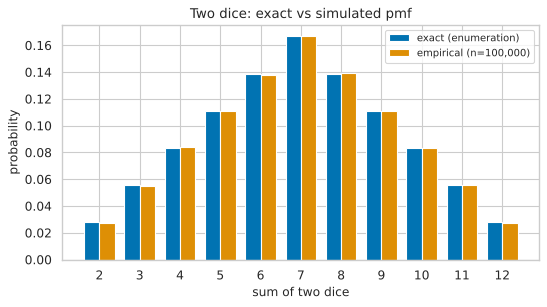

PosixPath('/home/claude/probability-simulation-laboratory/01_probability_fundamentals/results/exp1_2_two_dice_pmf.png')

In [5]:
# F. Implementation ------------------------------------------------------------------
# Omega -> list of tuples;  event "sum = s" -> function w: sum(w) == s;  P(A)=|A|/|Omega|
omega = f.sample_space_dice(2)
sums = np.arange(2, 13)
exact = {s: f.exact_probability(lambda w, s=s: sum(w) == s, omega) for s in sums}

n = 100_000
rolls = f.roll_dice(n, 2, rng)
s_sim = rolls.sum(axis=1)
emp = f.empirical_pmf(s_sim, sums)
exact_float = np.array([float(exact[s]) for s in sums])
counts = np.array([(s_sim == s).sum() for s in sums])

# G. Results ------------------------------------------------------------------------
table = pd.DataFrame({
    "exact (fraction)": [str(exact[s]) for s in sums],
    "exact": exact_float,
    "empirical": emp,
    "abs_diff": np.abs(emp - exact_float),
    "std_error": np.sqrt(exact_float * (1 - exact_float) / n),
}, index=pd.Index(sums, name="sum"))
table["diff_in_SE"] = (emp - exact_float) / table["std_error"]
table.to_csv(RESULTS / "exp1_2_two_dice_pmf.csv")
display(table)

fig, ax = plt.subplots(figsize=(7, 4))
w = 0.38
ax.bar(sums - w / 2, exact_float, w, label="exact (enumeration)")
ax.bar(sums + w / 2, emp, w, label=f"empirical (n={n:,})")
ax.set(xlabel="sum of two dice", ylabel="probability", title="Two dice: exact vs simulated pmf", xticks=sums)
ax.legend()
fig.tight_layout()
save_fig(fig, RESULTS, "exp1_2_two_dice_pmf.png")

In [6]:
# H. Theoretical vs empirical: total variation distance and chi-square goodness of fit
tv = 0.5 * np.abs(emp - exact_float).sum()
chi2, pval = stats.chisquare(counts, f_exp=n * exact_float)
print(f"total variation distance = {tv:.5f}")
print(f"Pearson chi-square = {chi2:.2f} on {len(sums)-1} d.f., p-value = {pval:.3f}")
print("largest |diff| in standard errors:", round(float(np.abs(table['diff_in_SE']).max()), 2))

total variation distance = 0.00214
Pearson chi-square = 3.04 on 10 d.f., p-value = 0.981
largest |diff| in standard errors: 1.02


**H. Theoretical versus empirical comparison.**

Every empirical frequency should lie within roughly $\pm 2$–$3$ standard errors of its exact value (the `diff_in_SE` column);
with 11 cells, one value beyond $2$ SE is not surprising. The $\chi^2$ test does not reject the exact model unless the
random sample happens to be unusual (a p-value below $0.05$ occurs by chance $5\%$ of the time — try other seeds).
Note also that the printed p-value need not be close to $1$: when the model is exactly right the p-value is uniformly distributed on $(0,1)$, so a very large value is no
better evidence for the model than a middling one.

**I. Interpretation.**

The simulation reproduces the triangular shape $\frac{6-|s-7|}{36}$. The exact calculation is *better* than simulation
here (it has no sampling error), which is a recurring lesson: simulate when exact solutions are unavailable or as a
check on code, not as a replacement for mathematics.

**J. Limitations.**

$\chi^2$ is an asymptotic test; it needs expected counts that are not tiny (here the smallest is about $2{,}800$, fine).
Failure to reject is not proof of fairness. The enumeration assumes fair dice.

**K. Research conclusion.**

A simulation of two fair dice agrees with the exact distribution obtained by counting outcomes; the discrepancies are
sampling noise of size $\approx\sqrt{P(1-P)/n}$.

**L. Further investigation.**

Load one die (e.g. $P(6)=0.25$) and use the $\chi^2$ test to detect the bias: how many rolls are needed for power $0.9$?
Derive the distribution of the sum of three dice and verify by enumeration and simulation.

## Experiment 1.3

**A. Experiment title.** Estimation of conditional probabilities $P(A\mid B)$ by restricting simulated trials to the event $B$, and the asymmetry $P(A\mid B)\neq P(B\mid A)$.

**B. Research question.** Can conditional probabilities be estimated by simulation, how large is the effective sample size, and is $P(A\mid B)$ the same as $P(B\mid A)$?

**C. Mathematical foundation.**

For $P(B)>0$, $P(A\mid B)=P(A\cap B)/P(B)$. Empirically, among the $n_B$ trials in which $B$ occurred, the fraction in which $A$ also occurred
estimates $P(A\mid B)$, with standard error $\sqrt{\hat p(1-\hat p)/n_B}$. The *effective* sample size is $n_B\approx nP(B)$, not $n$.
Take two dice $D_1,D_2$ and the events
$E$: "$D_1$ is even", $T$: "$S=D_1+D_2=8$", $H$: "$S\ge 10$", $\text{Six}$: "$D_1=6$", $\text{Twelve}$: "$S=12$".

**D. Theoretical prediction.**

By counting: $P(T\mid E)=\frac{3/36}{18/36}=\frac16$; $P(H\mid \text{Six})=\frac36=\frac12$; and the asymmetry example
$P(\text{Twelve}\mid\text{Six})=\frac16$ while $P(\text{Six}\mid\text{Twelve})=1$.

**E. Experimental design.**

Simulate $n=200{,}000$ rolls of two dice, evaluate each event as a boolean array, estimate each conditional probability with a Wilson 95% interval,
and compare with exact enumeration.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

In [7]:
# F. Implementation ------------------------------------------------------------------
omega = f.sample_space_dice(2)
events = {   # name -> (boolean function on one outcome (d1, d2))
    "E: D1 even":        lambda w: w[0] % 2 == 0,
    "T: sum = 8":        lambda w: sum(w) == 8,
    "H: sum >= 10":      lambda w: sum(w) >= 10,
    "Six: D1 = 6":       lambda w: w[0] == 6,
    "Twelve: sum = 12":  lambda w: sum(w) == 12,
}
queries = [("T: sum = 8", "E: D1 even"), ("H: sum >= 10", "Six: D1 = 6"),
           ("Twelve: sum = 12", "Six: D1 = 6"), ("Six: D1 = 6", "Twelve: sum = 12"),
           ("Six: D1 = 6", "H: sum >= 10")]

n = 200_000
rolls = f.roll_dice(n, 2, rng)
d1, d2 = rolls[:, 0], rolls[:, 1]
s = d1 + d2
sim = {"E: D1 even": d1 % 2 == 0, "T: sum = 8": s == 8, "H: sum >= 10": s >= 10,
       "Six: D1 = 6": d1 == 6, "Twelve: sum = 12": s == 12}      # vectorised versions of the same events

rows = []
for a, b in queries:
    exact_val = f.exact_conditional_probability(events[a], events[b], omega)
    est, n_b = f.estimate_conditional_probability(sim[a], sim[b])
    lo, hi = wilson_interval(int(round(est * n_b)), n_b)
    rows.append({"P(A | B)": f"P({a.split(':')[0]} | {b.split(':')[0]})", "exact": str(exact_val), "exact_float": float(exact_val),
                 "estimate": est, "n_B (effective)": n_b, "wilson_low": lo, "wilson_high": hi, "covers": lo <= float(exact_val) <= hi})
cond_table = pd.DataFrame(rows).set_index("P(A | B)")
cond_table.to_csv(RESULTS / "exp1_3_conditional.csv")
display(cond_table)

,exact,exact_float,estimate,n_B (effective),wilson_low,wilson_high,covers
P(A | B),,,,,,,
P(T | E),1/6,0.16667,0.16712,100274,0.16483,0.16944,True
P(H | Six),1/2,0.50000,0.50133,33543,0.49598,0.50668,True
P(Twelve | Six),1/6,0.16667,0.16567,33543,0.16173,0.16968,True
P(Six | Twelve),1,1.00000,1.00000,5557,0.99931,1.00000,True
P(Six | H),1/2,0.50000,0.50055,33595,0.49520,0.50590,True


**H. Theoretical versus empirical comparison.**

The Wilson intervals should cover the exact values in most (about $95\%$ each) cases — occasionally one will not. Notice the very different effective
sample sizes: conditioning on a rare event ($S=12$, probability $1/36$) leaves only about $n/36$ usable trials, so its interval is much wider.
$P(\text{Twelve}\mid\text{Six})=\tfrac16$ but $P(\text{Six}\mid\text{Twelve})=1$ shows that conditional probability is not symmetric.

**I. Interpretation.**

Conditioning means *restricting attention* to the trials where $B$ happened. The common error "$P(A\mid B)=P(B\mid A)$" (the *transposed
conditional*) is behind many real-world mistakes (courtroom statistics, medical testing — see Experiment 1.5).

**J. Limitations.**

Estimating $P(A\mid B)$ for a very rare $B$ by naive simulation is inefficient (large variance); Module 5 introduces importance sampling for this.
The Wilson intervals are approximate for small $n_B$.

**K. Research conclusion.**

Conditional probabilities can be estimated by filtering simulated trials on $B$; precision is governed by $n_B$, not $n$; and $P(A\mid B)\ne P(B\mid A)$ in general.

**L. Further investigation.**

Prove $P(A\mid B)P(B)=P(B\mid A)P(A)$ and use it to derive Bayes' theorem. Then explore *rejection sampling*: how many trials are wasted when $P(B)=10^{-3}$?

## Experiment 1.4

**A. Experiment title.** Testing independence: $P(A\cap B)$ versus $P(A)P(B)$, and pairwise versus mutual independence.

**B. Research question.** How do we recognise independent and dependent events, in theory and in simulated data? Does pairwise independence imply mutual independence?

**C. Mathematical foundation.**

$A,B$ are independent iff $P(A\cap B)=P(A)P(B)$. For dice: $A$="$D_1$ even", $B$="$S=7$", $C$="$S\ge10$".
Whatever $D_1$ is, exactly one value of $D_2$ makes $S=7$, so $P(B\mid A)=\tfrac16=P(B)$: **$A,B$ independent**. But
$P(C\mid A)=\frac{4/36}{18/36}=\frac29\ne\frac16=P(C)$: **$A,C$ dependent**.
Two fair coins give events $H_1$="first is heads", $H_2$="second is heads", $M$="the coins match". Each pair is independent
($P(H_1\cap M)=\tfrac14=\tfrac12\cdot\tfrac12$ etc.), yet $P(H_1\cap H_2\cap M)=\tfrac14\ne\tfrac18$: not mutually independent.
For simulated data we use Pearson's $\chi^2$ test of independence on the $2\times2$ table of counts.

**D. Theoretical prediction.**

Exact: $A,B$ independent; $A,C$ dependent; coin events pairwise independent but not mutually independent.
Simulation: for $(A,B)$ the product rule holds up to noise and the $\chi^2$ p-value is a draw from Uniform$(0,1)$ (so usually not small);
for $(A,C)$ the p-value is astronomically small at $n=100{,}000$.

**E. Experimental design.**

Use $n=100{,}000$ simulated pairs of dice for $(A,B)$ and $(A,C)$, and the same number of two-coin trials for the triple. Report
$\hat P(A\cap B)$, $\hat P(A)\hat P(B)$, their difference, and the $\chi^2$ p-value.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

In [8]:
# F. Implementation ------------------------------------------------------------------
# --- exact (enumeration) --------------------------------------------------------------
omega = f.sample_space_dice(2)
A = lambda w: w[0] % 2 == 0
B = lambda w: sum(w) == 7
C = lambda w: sum(w) >= 10
P = f.exact_probability
for name, X, Y in [("A,B", A, B), ("A,C", A, C)]:
    joint = P(lambda w: X(w) and Y(w), omega)
    print(f"exact  {name}:  P(X and Y) = {joint},  P(X)P(Y) = {P(X, omega) * P(Y, omega)},  independent: {joint == P(X, omega) * P(Y, omega)}")

coins = f.sample_space_dice(2, sides=2)          # outcomes (1,1),(1,2),(2,1),(2,2); 1 = heads
H1, H2, M = (lambda w: w[0] == 1), (lambda w: w[1] == 1), (lambda w: w[0] == w[1])
for nm, X, Y in [("H1,H2", H1, H2), ("H1,M", H1, M), ("H2,M", H2, M)]:
    print(f"coins {nm}: independent = {P(lambda w: X(w) and Y(w), coins) == P(X, coins) * P(Y, coins)}")
triple = P(lambda w: H1(w) and H2(w) and M(w), coins)
print(f"coins triple: P(H1 & H2 & M) = {triple} vs product {P(H1, coins) * P(H2, coins) * P(M, coins)} -> mutually independent: {triple == P(H1, coins) * P(H2, coins) * P(M, coins)}")

# --- simulation -------------------------------------------------------------------------
n = 100_000
rolls = f.roll_dice(n, 2, rng)
a_ = rolls[:, 0] % 2 == 0
b_ = rolls.sum(axis=1) == 7
c_ = rolls.sum(axis=1) >= 10

rows = []
for name, x, y in [("A,B (independent)", a_, b_), ("A,C (dependent)", a_, c_)]:
    table = np.array([[np.sum(x & y), np.sum(x & ~y)], [np.sum(~x & y), np.sum(~x & ~y)]])
    chi2, pval, *_ = stats.chi2_contingency(table, correction=False)
    rows.append({"pair": name, "P_hat(A and B)": np.mean(x & y), "P_hat(A) P_hat(B)": x.mean() * y.mean(),
                 "difference": np.mean(x & y) - x.mean() * y.mean(), "chi2": chi2, "p_value": pval})
indep_table = pd.DataFrame(rows).set_index("pair")
indep_table.to_csv(RESULTS / "exp1_4_independence.csv")
display(indep_table)

exact  A,B:  P(X and Y) = 1/12,  P(X)P(Y) = 1/12,  independent: True
exact  A,C:  P(X and Y) = 1/9,  P(X)P(Y) = 1/12,  independent: False
coins H1,H2: independent = True
coins H1,M: independent = True
coins H2,M: independent = True
coins triple: P(H1 & H2 & M) = 1/4 vs product 1/8 -> mutually independent: False


,P_hat(A and B),P_hat(A) P_hat(B),difference,chi2,p_value
pair,,,,,
"A,B (independent)",0.08514,0.08422,0.00092,2.44125,0.11818
"A,C (dependent)",0.11023,0.08324,0.02699,2101.59541,0.00000


**H. Theoretical versus empirical comparison.**

For $(A,B)$ the difference $\hat P(A\cap B)-\hat P(A)\hat P(B)$ is tiny (of order $10^{-3}$) and the $\chi^2$ test does not
reject independence; for $(A,C)$ the difference is clearly non-zero (exactly, $P(A\cap C)=\tfrac19$ whereas $P(A)P(C)=\tfrac12\cdot\tfrac16=\tfrac1{12}$)
and the p-value is essentially zero. The exact enumeration confirms the coin example is pairwise but not mutually independent.

**I. Interpretation.**

Independence is a *numerical equality of probabilities*, not a causal statement and not something visible by eye. Note
that "$A,B$ independent" does not mean "$A$ has nothing to do with $B$": $B$ is defined through $D_1$ yet independent of the parity of $D_1$.
Pairwise independence is *not enough* to factor three-way probabilities.

**J. Limitations.**

A non-rejecting test never proves independence (it only fails to find dependence at this sample size); a rejecting test at huge $n$ may detect
trivially small dependence. Here the events are exactly independent or clearly dependent, so these issues are not tested.

**K. Research conclusion.**

Independence can be verified exactly by enumeration and detected statistically by a $\chi^2$ test; pairwise independence $\not\Rightarrow$ mutual independence.

**L. Further investigation.**

Two random variables can be uncorrelated yet dependent (Module 2, Experiment 2.5). Investigate *conditional* independence: events dependent marginally
but independent given a third event.

## Experiment 1.5

**A. Experiment title.** Bayes' theorem for a screening test: the posterior $P(D\mid +)$ as a function of prevalence, sensitivity and specificity.

**B. Research question.** If a person tests positive on a quite accurate screening test, how likely is it that they actually have the disease?

**C. Mathematical foundation.**

Let $D$ = disease, $+$ = positive test. Sensitivity $=P(+\mid D)$, specificity $=P(-\mid D^c)$, prevalence (prior) $\pi=P(D)$. By the law of total probability
$P(+)=P(+\mid D)\pi+P(+\mid D^c)(1-\pi)$ and by Bayes' theorem
$$P(D\mid +)=\frac{\text{sens}\cdot\pi}{\text{sens}\cdot\pi+(1-\text{spec})(1-\pi)}.$$
With $\pi=1\%$, sens $=95\%$, spec $=90\%$ the posterior is $\dfrac{0.0095}{0.0095+0.099}\approx 8.76\%$. In natural frequencies: of $10{,}000$ people,
$100$ are diseased and $95$ test positive; of the $9{,}900$ healthy, $990$ test positive; so only $95$ of the $1{,}085$ positives are diseased.

**D. Theoretical prediction.**

$P(D\mid+)\approx0.0876$ (not $0.95$). The posterior increases with prevalence; for low prevalence even a high specificity leaves many false positives.
Simulation of $2$ million people should reproduce $0.0876$ with standard error $\sqrt{0.0876\cdot0.9124/n_+}$, where $n_+\approx 0.1085\cdot 2\times10^6$.

**E. Experimental design.**

(i) Simulate $2{,}000{,}000$ people, estimate $P(D\mid+)$ as the fraction of positives who are diseased. (ii) Sweep the prevalence from $0.1\%$ to $50\%$ for specificities
$0.80, 0.90, 0.99$, plot the exact posterior curve and overlay simulated points ($200{,}000$ people per point).

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

In [9]:
# F. Implementation ------------------------------------------------------------------
# P(D|+) = sens*prior / (sens*prior + (1-spec)*(1-prior))   ->  f.bayes_posterior
# simulation: disease ~ Bernoulli(prior);  positive | disease ~ Bernoulli(sens) ; positive | healthy ~ Bernoulli(1-spec)
prior, sens, spec = 0.01, 0.95, 0.90
exact_post = f.bayes_posterior(prior, sens, spec)

n = 2_000_000
disease, positive = f.simulate_screening(n, prior, sens, spec, rng)
est, n_pos = f.estimate_conditional_probability(disease, positive)
lo, hi = wilson_interval(int(round(est * n_pos)), n_pos)
tp, fp = int((disease & positive).sum()), int((~disease & positive).sum())
print(f"exact posterior  P(D|+) = {exact_post:.5f}")
print(f"simulated        P(D|+) = {est:.5f}   (95% Wilson interval {lo:.5f} .. {hi:.5f}, n_+ = {n_pos:,})")
print(f"true positives = {tp:,}, false positives = {fp:,}  -> {fp/tp:.1f} false positives per true positive")

# natural-frequency table for 10,000 people
nf = pd.DataFrame({"diseased": [95, 5], "healthy": [990, 8910]}, index=["test +", "test -"])
display(nf)

exact posterior  P(D|+) = 0.08756
simulated        P(D|+) = 0.08728   (95% Wilson interval 0.08610 .. 0.08847, n_+ = 218,059)
true positives = 19,032, false positives = 199,027  -> 10.5 false positives per true positive


,diseased,healthy
test +,95,990
test -,5,8910


max |exact - simulated| over the grid: 0.0055


,specificity,prevalence,exact,simulated,n_positive,abs_error
0,0.8,0.001,0.00473,0.00448,40193,0.00025
1,0.8,0.003,0.01409,0.01392,40600,0.00018
2,0.8,0.010,0.04578,0.04393,41315,0.00185
3,0.8,0.030,0.12809,0.12598,44373,0.00211
4,0.8,0.100,0.34545,0.34490,54834,0.00056
5,0.8,0.300,0.67059,0.66861,85088,0.00197
6,0.8,0.500,0.82609,0.82547,115368,0.00062


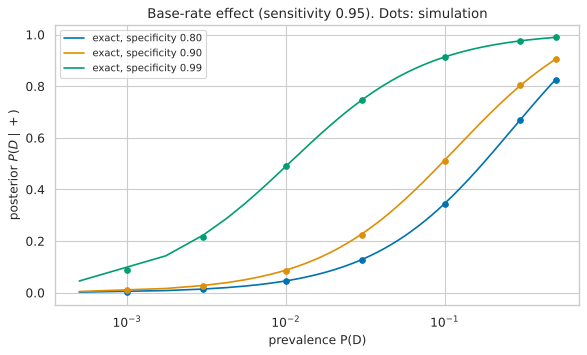

In [10]:
# G. Results: posterior vs prevalence (exact curves, simulated points)
prev_grid = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 0.5])
fine = np.linspace(0.0005, 0.5, 400)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
rows = []
for sp_ in (0.80, 0.90, 0.99):
    line, = ax.plot(fine, f.bayes_posterior(fine, 0.95, sp_), label=f"exact, specificity {sp_:.2f}")
    sim_pts = []
    for pv in prev_grid:
        d, pos = f.simulate_screening(200_000, pv, 0.95, sp_, rng)
        e, nb_ = f.estimate_conditional_probability(d, pos)
        sim_pts.append(e)
        rows.append(dict(specificity=sp_, prevalence=pv, exact=f.bayes_posterior(pv, 0.95, sp_), simulated=e, n_positive=nb_))
    ax.plot(prev_grid, sim_pts, "o", color=line.get_color(), ms=5)
ax.set(xscale="log", xlabel="prevalence P(D)", ylabel=r"posterior $P(D\mid +)$", title="Base-rate effect (sensitivity 0.95). Dots: simulation")
ax.legend()
fig.tight_layout()
save_fig(fig, RESULTS, "exp1_5_bayes_posterior.png")
bayes_table = pd.DataFrame(rows)
bayes_table["abs_error"] = (bayes_table.exact - bayes_table.simulated).abs()
bayes_table.to_csv(RESULTS / "exp1_5_bayes_table.csv", index=False)
print("max |exact - simulated| over the grid:", round(bayes_table.abs_error.max(), 4))
display(bayes_table.head(7))

**H. Theoretical versus empirical comparison.**

The simulated posterior is within its standard error of the exact value $0.0876$; the natural-frequency table makes the arithmetic transparent.
In the sweep the simulated dots sit on the exact curves to within sampling error (the largest absolute deviation is printed above). Precision is poorest where
few people test positive — low prevalence combined with high specificity, see the `n_positive` column.

**I. Interpretation.**

A test that is "95% sensitive and 90% specific" produces *mostly false positives* when the disease is rare, because
$P(+\mid D)$ and $P(D\mid +)$ are different quantities. This is the **base-rate fallacy**, and the same structure appears in fraud detection,
spam filtering, and signal detection in finance: a rule that flags rare events will flag many false alarms.

**J. Limitations.**

Real populations are heterogeneous (prevalence differs by group), tests are not conditionally independent across repeat testing,
and the sensitivity/specificity values are themselves estimated with uncertainty. This is a stylised model with illustrative numbers, not medical advice.

**K. Research conclusion.**

Bayes' theorem converts $P(\text{test}\mid\text{disease})$ into $P(\text{disease}\mid\text{test})$ and requires the prior; with a low prior, the posterior stays low even after a positive result.

**L. Further investigation.**

Apply the test twice (assume conditional independence given $D$): derive and simulate the posterior after two positives. Treat the prior as uncertain
(Beta distributed) and examine how that uncertainty propagates to the posterior (hierarchical/Bayesian Monte Carlo).

## Experiment 1.6

**A. Experiment title.** Combinatorial probability: the birthday collision probability $1-\prod_{i=0}^{n-1}\frac{365-i}{365}$ and the Monty Hall switching probability $2/3$.

**B. Research question.** How large must a group be for a shared birthday to be more likely than not? Does switching doors in the Monty Hall game help?

**C. Mathematical foundation.**

**Birthday.** Assume $n$ people have independent birthdays uniform over $365$ days. The number of equally likely birthday assignments is $365^n$; assignments with all
birthdays distinct number $365\cdot364\cdots(365-n+1)$. Hence
$P(\text{no match})=\prod_{i=0}^{n-1}\frac{365-i}{365}$ and $P(\text{match})=1-\prod_{i=0}^{n-1}\left(1-\frac{i}{365}\right)\approx 1-e^{-n(n-1)/730}$.
**Monty Hall.** The prize is behind door $X\sim\text{Uniform}\{1,2,3\}$; you pick door 1; the host (who knows $X$) opens a goat door $\neq$ your pick.
$P(X=1)=\tfrac13$. If you stay you win iff $X=1$. If you switch you win iff $X\ne1$, because the host's action leaves the *only* other door as the prize
in exactly those cases: $P(\text{win}\mid\text{switch})=\tfrac23$.

**D. Theoretical prediction.**

$P(\text{match})$ first exceeds $0.5$ at $n=23$ ($\approx 0.5073$) and reaches $\approx0.97$ at $n=50$. Monty Hall: stay $\to\tfrac13$, switch $\to\tfrac23$.

**E. Experimental design.**

Birthday: for $n=1,\dots,60$, simulate $40{,}000$ groups each and compare with the exact formula. Monty Hall: simulate $300{,}000$ games, with the host's rule coded
explicitly (not the shortcut "switch wins iff first pick was wrong"), for both strategies.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

first n with P(match) > 0.5 (exact): 23   P = 0.5073
n = 50: exact 0.9704, simulated 0.9715


,theory,simulated,wilson_low,wilson_high,covers
strategy,,,,,
stay,0.33333,0.33162,0.32994,0.33331,False
switch,0.66667,0.66752,0.66583,0.66920,True


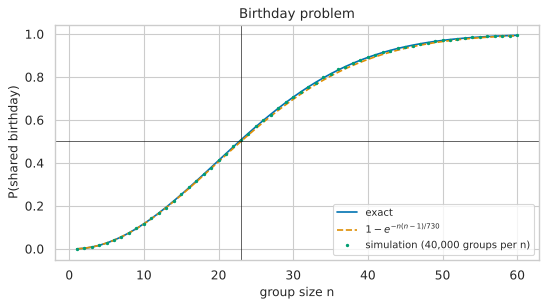

In [11]:
# F. Implementation ------------------------------------------------------------------
ns = np.arange(1, 61)
exact_b = np.array([f.birthday_exact(k) for k in ns])
sim_b = np.array([f.birthday_simulated(k, 40_000, rng) for k in ns])
se_b = np.sqrt(exact_b * (1 - exact_b) / 40_000)
approx_b = 1 - np.exp(-ns * (ns - 1) / 730)

first_half = int(ns[np.argmax(exact_b > 0.5)])
print(f"first n with P(match) > 0.5 (exact): {first_half}   P = {f.birthday_exact(first_half):.4f}")
print(f"n = 50: exact {f.birthday_exact(50):.4f}, simulated {sim_b[49]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, exact_b, label="exact"); ax.plot(ns, approx_b, "--", label=r"$1-e^{-n(n-1)/730}$")
ax.plot(ns, sim_b, ".", ms=4, label="simulation (40,000 groups per n)")
ax.axhline(0.5, color="k", lw=0.6); ax.axvline(first_half, color="k", lw=0.6)
ax.set(xlabel="group size n", ylabel="P(shared birthday)", title="Birthday problem")
ax.legend(); fig.tight_layout(); save_fig(fig, RESULTS, "exp1_6_birthday.png")

# Monty Hall -----------------------------------------------------------------------
n_games = 300_000
rows = []
for strategy, sw, truth in [("stay", False, 1 / 3), ("switch", True, 2 / 3)]:
    est = f.monty_hall(n_games, sw, rng)
    lo, hi = wilson_interval(int(round(est * n_games)), n_games)
    rows.append({"strategy": strategy, "theory": truth, "simulated": est, "wilson_low": lo, "wilson_high": hi, "covers": lo <= truth <= hi})
monty = pd.DataFrame(rows).set_index("strategy")
monty.to_csv(RESULTS / "exp1_6_monty_hall.csv")
display(monty)

In [12]:
# H. Theoretical vs empirical (birthday): how many of the 60 simulated points are within 2 and 3 standard errors?
valid = se_b > 0                       # n = 1 has P(match) = 0 exactly, so no sampling error to scale by
z = (sim_b[valid] - exact_b[valid]) / se_b[valid]
print(f"|z| < 2 for {np.mean(np.abs(z) < 2):.0%} of group sizes (about 95% expected); |z| < 3 for {np.mean(np.abs(z) < 3):.0%} (about 99.7% expected)")
print(f"max |exact - approximation| over n = 1..60: {np.max(np.abs(exact_b - approx_b)):.4f}")

|z| < 2 for 98% of group sizes (about 95% expected); |z| < 3 for 100% (about 99.7% expected)
max |exact - approximation| over n = 1..60: 0.0103


**H. Theoretical versus empirical comparison.**

The simulated birthday probabilities track the exact curve; the share of points within $2$ SE is close to the nominal $95\%$. The exponential approximation
is accurate to about a percentage point. The Monty Hall simulation gives about $1/3$ for staying and about $2/3$ for switching. In the seeded run saved here the Wilson interval for "stay" just misses $1/3$
(by roughly two standard errors) — something 95% intervals do about once in twenty times, so it is not evidence against the theory. Change the seed and watch which interval misses.

**I. Interpretation.**

Intuition fails in both problems: the birthday problem counts all $\binom n2$ *pairs* (253 pairs at $n=23$), not matches with *you*; Monty Hall hinges on the
host's *knowledge*, which makes his action informative. Combinatorial reasoning plus a short simulation is a powerful way to check surprising results.

**J. Limitations.**

The birthday model assumes uniform independent birthdays (real births are seasonal, which *increases* collision probability) and ignores 29 February. Monty Hall
results change if the host does not know where the prize is, or picks randomly — a different model with a different answer.

**K. Research conclusion.**

$23$ people suffice for a more-likely-than-not shared birthday; switching doors wins with probability $2/3$. Both agree with simulation.

**L. Further investigation.**

Simulate the "host does not know" variant (random door opened, condition on no prize shown) and show the switching advantage disappears. Estimate the
expected number of people needed for a first match, and the probability of a *triple* birthday.

## Exercises (attempt on paper first — no solutions are given here)

1. For three coin tosses write $\Omega$, list the event "exactly two heads", and compute its probability. Why is "number of heads" *not* a valid sample space with equally likely outcomes?
2. Prove from the axioms: (a) $P(\emptyset)=0$; (b) $A\subseteq B\Rightarrow P(A)\le P(B)$; (c) $P(A\cup B)=P(A)+P(B)-P(A\cap B)$.
3. A fair die is rolled 60 times and 4 sixes appear. What are the expected count, the standard deviation of the count, and the z-score? Does this contradict $P(\text{six})=1/6$?
4. Show that if $A$ and $B$ are independent then so are $A$ and $B^c$.
5. Give your own example (not in this notebook) of events that are pairwise independent but not mutually independent.
6. In Experiment 1.5 compute the posterior if the test is repeated and is positive twice (assume conditional independence given disease status). Then check by simulation.
7. A stock is "up", "down" or "flat" tomorrow. Someone assigns probability $1/3$ to each. Which axioms hold? What assumption is doing the real work? How would you *estimate* these probabilities from data, and what could go wrong?
8. (Challenge) Show that the probability that $n$ people have no shared birthday is at most $e^{-n(n-1)/(2\cdot365)}$, using $1-x\le e^{-x}$.

## Summary of Module 1
* A probability model is $(\Omega,\mathcal F,P)$; events are subsets; probabilities satisfy three axioms.
* Relative frequency estimates probability with standard error $\sqrt{p(1-p)/n}$ — precision grows like $\sqrt n$.
* Conditional probability restricts the sample space; effective sample size is $n_B$.
* Independence is a product rule; pairwise $\neq$ mutual.
* Bayes' theorem needs the prior; base rates dominate for rare events.

**Next:** Module 2 — random variables and the eleven distributions.